# Incendios en el Perú vistos desde el espacio · Chichas y Río Tambo, octubre de 2026

**¿Cuánto se quemó, qué se quemó y qué viviendas están expuestas?**

Luis Gabriel Guevara Vega · Python Intermedio · Diplomatura de QLab · PUCP ·
datos al **20 de octubre de 2026**

El monitor del profesor detectó la temporada de incendios más intensa desde 2012. Este
notebook toma dos incendios activos, mide su **área quemada con Sentinel-2 (dNBR)**, la
cruza con **cobertura del suelo (WorldCover)** y con **Google Open Buildings** para ubicar
las edificaciones expuestas, y suma el **clima de Open-Meteo**. Todo con datos abiertos,
sin claves, en CPU.

| Paso | Qué hacemos |
|---|---|
| 1 | Focos de calor VIIRS del Perú (INPE + validación con NASA FIRMS) |
| 2 | De focos a incendios: ≤ 1 km y ≤ 48 h |
| 3 | Elegir imágenes Sentinel-2 **mirando las nubes dentro de la zona** |
| 4 | NBR, dNBR y un umbral que se ajusta al ruido |
| 5 | Validar antes de creer: mirar la cicatriz |
| 6 | La lección de Curahuasi: ¿cuánto cambian las hectáreas con otras decisiones? |
| 7 | ¿Qué se quemó? WorldCover y distritos |
| 8 | ¿Qué viviendas están expuestas? Google Open Buildings |
| 9 | Clima: ¿puede crecer esta semana? |
| 10 | Río Tambo con el mismo flujo |
| 11 | Tres hallazgos con números y limitaciones |

El código pesado vive en `src/` (una función por idea). Aquí se usa paso a paso.

## 0 · Preparación

```bash
uv sync                          # instala todo desde pyproject.toml
uv run python src/focos.py       # descarga y agrupa los focos (1–2 min)
uv run python src/open_buildings.py   # recorta Open Buildings (lee ~1 GB, una sola vez)
```

In [1]:
import json, sys, warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import config, focos as F, sentinel as s2, cruces, figuras, pipeline
from config import INCENDIOS, PROCESSED, CORTE

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"figure.dpi": 100})

## 1 · Focos de calor: qué arde y dónde

Un **foco de calor** es un píxel de 375 m donde el satélite VIIRS midió más calor del
esperado. No es un incendio: una quema agrícola, un incendio grande o una fábrica pueden
dar focos. Usamos solo los tres satélites VIIRS (S-NPP, NOAA-20 y NOAA-21), que pasan por el
Perú alrededor de la 01:30 y las 13:30 h.

INPE Queimadas publica un CSV diario de Sudamérica (guarda ~30 días). Lo cruzamos con los
límites distritales del INEI: el país lo decide el polígono, no una columna de texto.

In [2]:
focos_peru = gpd.read_parquet(PROCESSED / "focos_peru.parquet")
print(f"{len(focos_peru):,} focos VIIRS en el Perú, del {focos_peru.fecha.min():%d %b} al {focos_peru.fecha.max():%d %b %Y}")
focos_peru.groupby("satelite").size().rename("focos").to_frame()

60,761 focos VIIRS en el Perú, del 21 Sep al 20 Oct 2026


,focos
satelite,
NOAA-20,20071
NOAA-21,19537
NPP-375,21153


**Validar la fuente.** Los mismos tres satélites están en NASA FIRMS. Si INPE y FIRMS no
coinciden en los días que comparten, algo está mal (zona horaria, duplicados, país).

In [3]:
v = pd.read_csv(PROCESSED / "validacion_inpe_firms.csv", index_col=0)
v

,INPE,FIRMS,diferencia_%
satelite,,,
NOAA-20,2573,2448,5.11
NOAA-21,2649,2613,1.38
NPP-375,3017,2883,4.65


Diferencias de +1 % a +5 %: las dos fuentes cuentan lo mismo. INPE da un poco más porque
completa sus archivos con pasadas tardías.

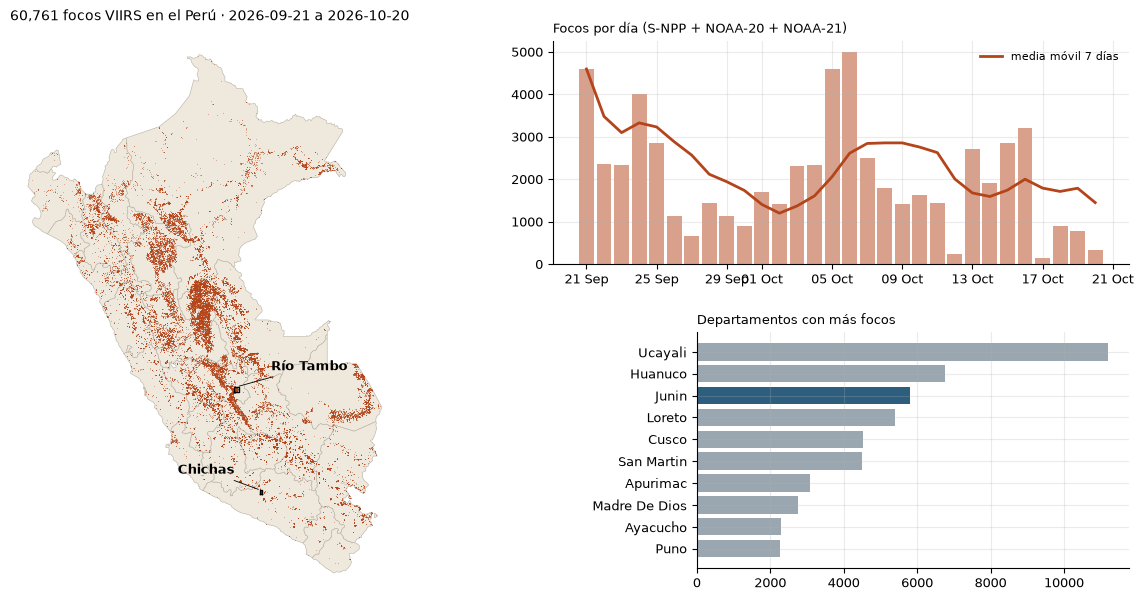

In [4]:
fig = figuras.nacional()
plt.show()

## 2 · De focos a incendios

Regla del profesor: dos focos son del **mismo incendio** si están a ≤ 1 km y a ≤ 48 h. Con
esa regla los focos se encadenan (componentes conexas de un grafo).

In [5]:
incendios = pd.read_csv(PROCESSED / "incendios_peru.csv", parse_dates=["inicio", "ultimo"])
incendios.head(8)[["distrito", "provincia", "departamento", "focos", "inicio", "ultimo", "frp_total"]]

,distrito,provincia,departamento,focos,inicio,ultimo,frp_total
0,CURAHUASI,ABANCAY,APURIMAC,839,2026-10-06 13:00:00,2026-10-20 12:54:00,"10,873.90"
1,RIO TAMBO,SATIPO,JUNIN,390,2026-10-13 13:06:00,2026-10-16 14:10:00,"3,719.70"
2,SICUANI,CANCHIS,CUSCO,235,2026-10-03 12:52:00,2026-10-07 01:03:00,"2,251.20"
3,SAN PEDRO DE CACHORA,ABANCAY,APURIMAC,235,2026-10-06 13:00:00,2026-10-16 14:08:00,"6,568.20"
4,COYLLURQUI,COTABAMBAS,APURIMAC,179,2026-10-01 12:54:00,2026-10-06 13:56:00,"3,708.10"
5,CHUMPI,PARINACOCHAS,AYACUCHO,178,2026-10-02 12:34:00,2026-10-06 13:56:00,"4,388.00"
6,ALTO PICHIGUA,ESPINAR,CUSCO,178,2026-10-05 12:34:00,2026-10-07 01:03:00,"9,670.00"
7,SAN CRISTOBAL,MARISCAL NIETO,MOQUEGUA,152,2026-10-11 13:06:00,2026-10-14 14:25:00,"1,545.40"


El incendio de **Río Tambo** (Satipo, Junín) es el segundo más grande del país en número de
focos, detrás de Curahuasi. **Chichas** (Condesuyos, Arequipa) es más chico, pero ardió en la
sierra: 130 focos en dos días. Elegimos los dos: selva y sierra, para ver qué cambia.

## 3 · Elegir las imágenes: las nubes de la zona, no las de la escena

Una escena Sentinel-2 cubre 110 × 110 km. Su «% de nubes» no dice nada sobre los 10 km que
nos importan. Medimos las nubes **dentro de la zona** con la capa SCL (clasificación de
escena que trae el producto L2A).

In [6]:
cfg = INCENDIOS["chichas"]
nubes = s2.nubes_por_fecha(cfg["bbox"], "2026-10-01", CORTE)
nubes

,fecha,nubes_zona_%,nubes_escena_%
0,2026-10-03,0.30,0.00
1,2026-10-05,0.10,0.10
2,2026-10-07,0.10,0.20
3,2026-10-08,0.20,0.40
4,2026-10-10,0.10,0.00
5,2026-10-13,0.20,2.60
6,2026-10-15,0.00,0.30
7,2026-10-17,0.40,0.10
8,2026-10-18,1.60,0.00
9,2026-10-20,13.10,26.60


Decisiones para Chichas (los focos empiezan el 16 de octubre):

- **Antes: 15 oct**, 0 % de nubes en la zona, un día antes del fuego.
- **Después: 20 oct**, la más reciente; tiene ~13 % de nubes, que se rellenan con la del
  **18 oct** (sin nubes). La del 17 se descarta: el fuego estaba en plena actividad.

## 4 · NBR, dNBR y el umbral

$$NBR = \frac{NIR - SWIR_2}{NIR + SWIR_2} \qquad dNBR = NBR_{antes} - NBR_{después}$$

La vegetación sana refleja mucho en el infrarrojo cercano (B8A) y poco en el de onda corta
(B12). Al quemarse se invierte. Dos detalles que si se olvidan dan números falsos:

1. **El desfase de +1000.** Desde 2022 (línea base 04.00) los DN de Sentinel-2 traen +1000.
   Sin restarlo, el NBR sale sesgado.
2. **Lo que no puede arder.** Agua, playas de río y roca cambian entre fechas y simulan
   «quemado». Los excluimos con SCL (agua) y WorldCover (suelo desnudo, nieve, agua).

In [7]:
cobertura = cruces.worldcover(cfg["bbox"])
fz = focos_peru.cx[cfg["bbox"][0]:cfg["bbox"][2], cfg["bbox"][1]:cfg["bbox"][3]]
ev = s2.analizar(cfg, fz, excluir=np.isin(cobertura.values, cruces.SIN_COMBUSTIBLE))

print("antes  :", [(e["fecha"], f'{e["nubes_pct"]:.1f} % nubes') for e in ev["pre"]["escenas"]])
print("después:", [(e["fecha"], f'{e["nubes_pct"]:.1f} % nubes') for e in ev["post"]["escenas"]],
      f'→ cobertura sin nubes {ev["post"]["cobertura_pct"]:.0f} %')
print(f'grilla: {ev["dnbr"].shape[0]} × {ev["dnbr"].shape[1]} píxeles de 20 m')

antes  : [('2026-10-15', '0.0 % nubes')]
después: [('2026-10-20', '12.5 % nubes'), ('2026-10-18', '0.0 % nubes')] → cobertura sin nubes 100 %
grilla: 726 × 544 píxeles de 20 m


**¿Qué umbral?** El USGS (Key y Benson) clasifica la severidad así: < 0,10 no quemado,
0,10–0,27 baja, 0,27–0,44 moderada-baja, 0,44–0,66 moderada-alta, > 0,66 alta. Muchos
trabajos usan 0,27 para «quemado». Pero el ruido depende del par de imágenes: nubes finas,
humo, sombras, fenología.

Lo medimos: el dNBR en **zonas de control sin ningún foco a más de 3 km** debería ser
cero. Su percentil 95 es cuánto «quema» el puro ruido. Umbral = máx(0,10; p95 del ruido).

{'pixeles_control_pct': 17.43285123966942, 'media': -0.004757045768201351, 'p95': 0.09844541549682617, 'umbral': 0.1}


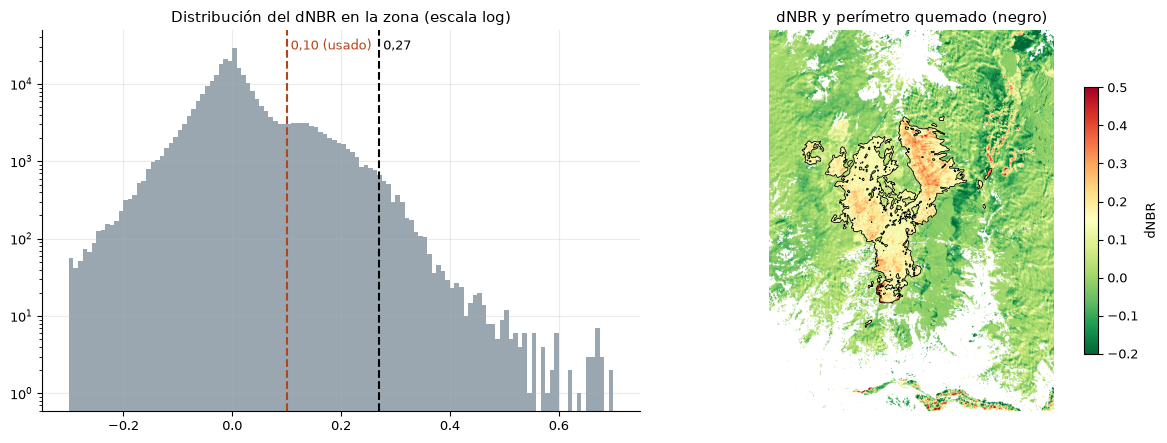

In [8]:
print(ev["ruido"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
v = s2.suavizar(ev["dnbr"])
ax[0].hist(v[np.isfinite(v)], bins=120, range=(-0.3, 0.7), color="#9aa7b0")
for u, c, t in [(0.10, "#B4441A", "0,10 (usado)"), (0.27, "k", "0,27")]:
    ax[0].axvline(u, color=c, ls="--"); ax[0].text(u, ax[0].get_ylim()[1] * 0.9, " " + t, color=c)
ax[0].set_yscale("log"); ax[0].set_title("Distribución del dNBR en la zona (escala log)")
im = ax[1].imshow(ev["dnbr"].values, cmap="RdYlGn_r", vmin=-0.2, vmax=0.5)
ax[1].contour(ev["quemado"].astype(int), levels=[0.5], colors="k", linewidths=0.6)
plt.colorbar(im, ax=ax[1], shrink=0.7, label="dNBR"); ax[1].set_axis_off()
ax[1].set_title("dNBR y perímetro quemado (negro)")
plt.tight_layout(); plt.show()

En Chichas el ruido es bajo (p95 ≈ 0,10): bastan 5 días entre imágenes y el cielo de la
sierra está limpio. **Sembrado:** solo cuentan las manchas quemadas que tocan un foco VIIRS
ocurrido entre las dos imágenes (a ≤ 750 m). Así no se cuela un cambio que no es fuego.

In [9]:
print(f'Área quemada en Chichas: {ev["quemado"].sum() * s2.HA_PIXEL:,.0f} ha')
ev["severidad"]

Área quemada en Chichas: 1,475 ha


,clase,dnbr_desde,ha
0,Baja,0.10,"1,368.96"
1,Moderada-baja,0.27,102.52
2,Moderada-alta,0.44,2.08
3,Alta,0.66,1.56


## 5 · Validar antes de creer

El número no basta: hay que **mirar** la imagen. En infrarrojo (B12-B8A-B4) lo quemado
se ve rojo oscuro casi negro.

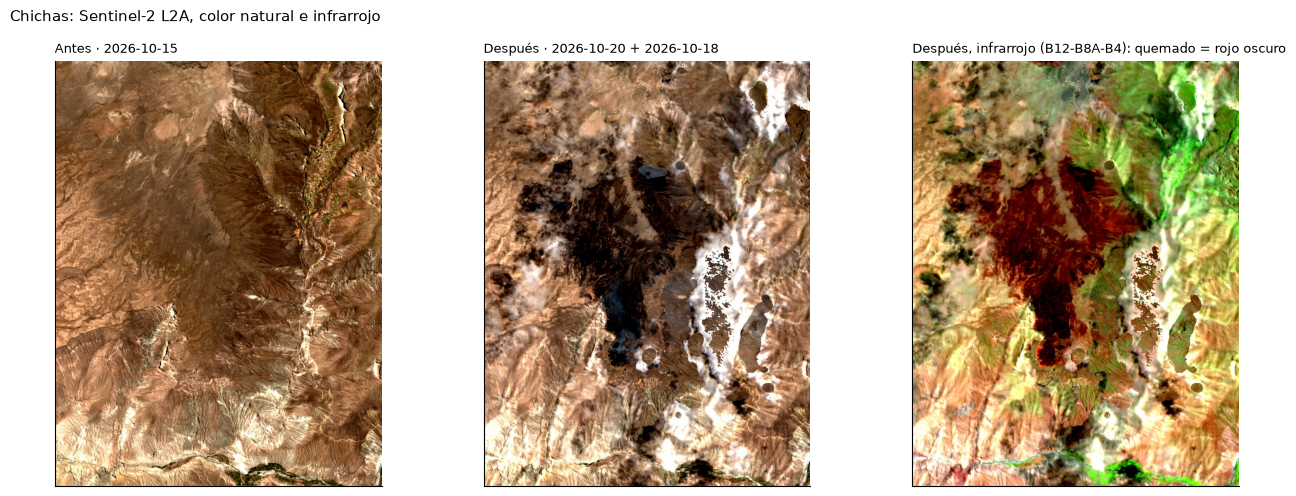

In [10]:
fig = figuras.antes_despues("chichas"); plt.show()

La cicatriz oscura del 20 de octubre coincide con el perímetro. Y la mayor parte cae en
**severidad baja (0,10–0,27)**: en pastizal de puna el fuego consume pasto seco, deja la
tierra visible y el NBR cae poco. **Con el umbral de 0,27 se habría perdido más del 90 %
del área quemada.** Esta es la decisión de método más importante del trabajo.

## 6 · La lección de Curahuasi: el mismo incendio, otras decisiones

El profe mostró Curahuasi con 696 a 2 782 ha según el método. Repetimos el ejercicio.

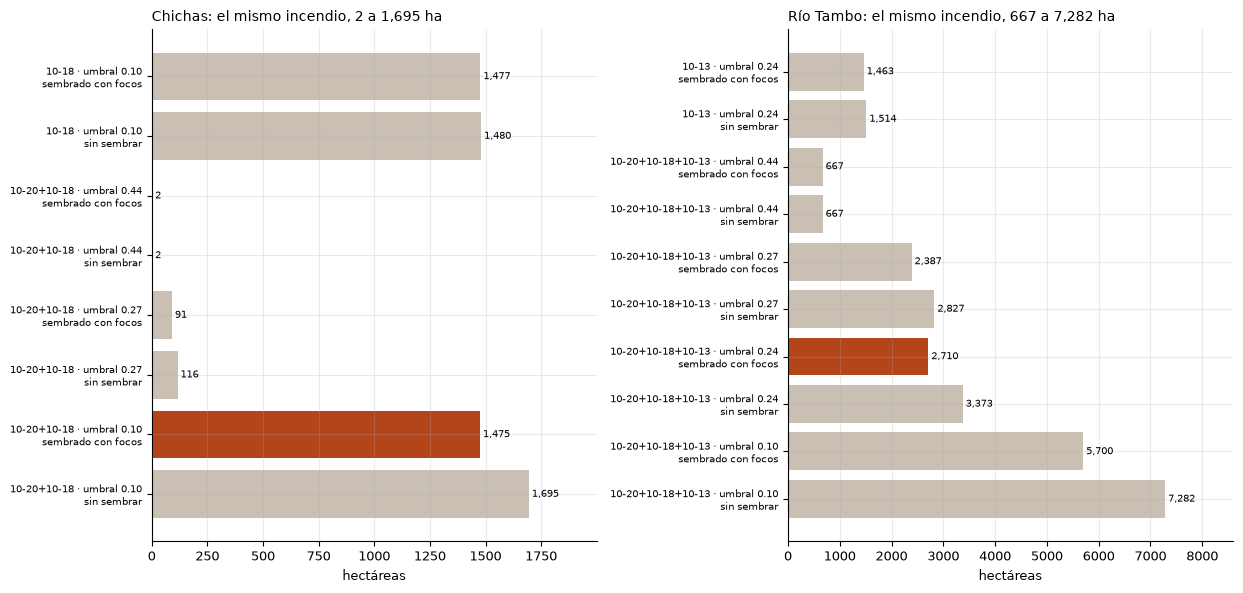

In [11]:
fig = figuras.sensibilidad(); plt.show()

- En **Chichas** el umbral lo es todo: 0,27 da ~90 ha; 0,10 da ~1 475 ha. Las fechas casi no
  importan (18 o 20 de octubre dan lo mismo) porque el cielo estaba limpio.
- En **Río Tambo** importa todo: con la imagen del 13 de octubre (sin los pulsos del 13 al
  19) se ven ~1 460 ha; con el compuesto hasta el 20, ~2 700. Sin sembrar con focos y con
  umbral 0,10, el ruido de la selva infla a más de 7 000 ha.

Por eso el README reporta siempre: **fechas, % de nubes, umbral y zona**.

## 7 · ¿Qué se quemó? ¿Dónde?

ESA WorldCover 2021 (10 m) se carga en la misma grilla de 20 m que el dNBR. Cruzar es contar
píxeles: no hace falta `zonal_stats` porque las dos capas comparten la grilla.

In [12]:
r_ch = json.loads((PROCESSED / "chichas" / "resumen.json").read_text(encoding="utf-8"))
display(pd.DataFrame(r_ch["por_cobertura"]))
pd.DataFrame(r_ch["por_distrito"])

,cobertura,ha,%
0,Pastizal,"1,061.60",72.00
1,Matorral,411.30,27.90
2,Bosque,2.00,0.10
3,Construido,0.10,0.00
4,Cultivo,0.00,0.00


,distrito,provincia,departamento,ha
0,Chichas,Condesuyos,Arequipa,"1,026.60"
1,Toro,La Union,Arequipa,448.60


El fuego de Chichas cruzó el límite distrital: **un tercio del área quemada está en Toro
(provincia La Unión)**. Un reporte por distrito que solo mire Chichas lo subestima.

## 8 · ¿Qué viviendas están expuestas? Google Open Buildings

[Google Open Buildings v3](https://sites.research.google/open-buildings/) tiene polígonos de
edificaciones detectadas con IA sobre imágenes de alta resolución (cobertura de América
Latina, imágenes hasta ~2023). Cada fila trae su área y una `confidence` ≥ 0,65.

Los archivos vienen por celda S2 de nivel 4 (340 MB para Chichas, 700 MB para Río Tambo).
`src/open_buildings.py` los lee por partes y guarda solo la zona.

In [13]:
ed = gpd.read_parquet(config.INTERIM / "edificios_chichas.parquet")
print(f"{len(ed):,} edificaciones en la zona de Chichas · área mediana {ed.area_in_meters.median():.0f} m²")
ed.head(3)

602 edificaciones en la zona de Chichas · área mediana 43 m²


,latitude,longitude,area_in_meters,confidence,full_plus_code,geometry
0,-15.46,-72.95,89.83,0.89,57P9G3R3+93R6,"POLYGON ((-72.9473 -15.45903, -72.94742 -15.45..."
1,-15.61,-73.08,32.54,0.84,57P89WVC+43RW,"POLYGON ((-73.07981 -15.60714, -73.07987 -15.6..."
2,-15.55,-72.92,34.39,0.85,57P9F33J+4V27,"POLYGON ((-72.91783 -15.54722, -72.91788 -15.5..."


**«Expuesta» no significa «se va a quemar».** Es un índice 0–100 con reglas explícitas,
para ordenar dónde mirar primero:

| Componente | Puntos | Regla |
|---|---|---|
| Proximidad | 50 | lineal: 50 en el borde del fuego, 0 a 2 km. «Fuego» = área quemada + focos de los últimos 3 días |
| Viento | 20 | la edificación queda a ±45° de hacia dónde sopla el viento de la tarde (Open-Meteo, 21–23 oct) |
| Pendiente | 15 | está más arriba que el punto de fuego más cercano (el fuego sube más rápido) |
| Combustible | 15 | fracción de vegetación en ~100 m alrededor (WorldCover) |

Categorías: **alta** ≥ 60, **media** 35–60, **baja** < 35; aparte, las que ya están dentro
del área quemada.

In [14]:
ex = gpd.read_file(PROCESSED / "chichas" / "edificaciones_expuestas.geojson")
display(ex.categoria.value_counts().rename("edificaciones").to_frame())
cols = ["full_plus_code", "area_in_meters", "dist_fuego_m", "a_favor_del_viento", "cuesta_arriba",
        "vegetacion_100m", "indice_exposicion", "categoria"]
ex.sort_values("indice_exposicion", ascending=False)[cols].head(10)

,edificaciones
categoria,
Fuera de 2 km,478
Media,64
Alta,57
Dentro del área quemada,2
Baja,1


,full_plus_code,area_in_meters,dist_fuego_m,a_favor_del_viento,cuesta_arriba,vegetacion_100m,indice_exposicion,categoria
239,57P9G2CX+V8R8,50.27,7.83,True,False,0.98,84.60,Alta
347,57P9G2FX+59J3,24.82,1.29,True,False,0.97,84.50,Alta
358,57P9G2FX+5969,92.34,3.04,True,False,0.97,84.40,Alta
506,57P9G2CX+X8G5,77.85,16.18,True,False,0.98,84.30,Alta
340,57P9G2CX+M73F,65.64,16.72,True,False,0.97,84.10,Alta
9,57P9G2CX+V96G,57.78,21.86,True,False,0.97,84.00,Alta
247,57P9G2CX+Q9FH,112.37,25.68,True,False,0.97,83.90,Alta
4,57P9G2CX+VCMP,81.55,37.95,True,False,0.97,83.60,Alta
534,57P9G2CX+QCRF,86.10,34.23,True,False,0.97,83.60,Alta
208,57P9G2CX+RCW2,51.67,39.63,True,False,0.97,83.50,Alta


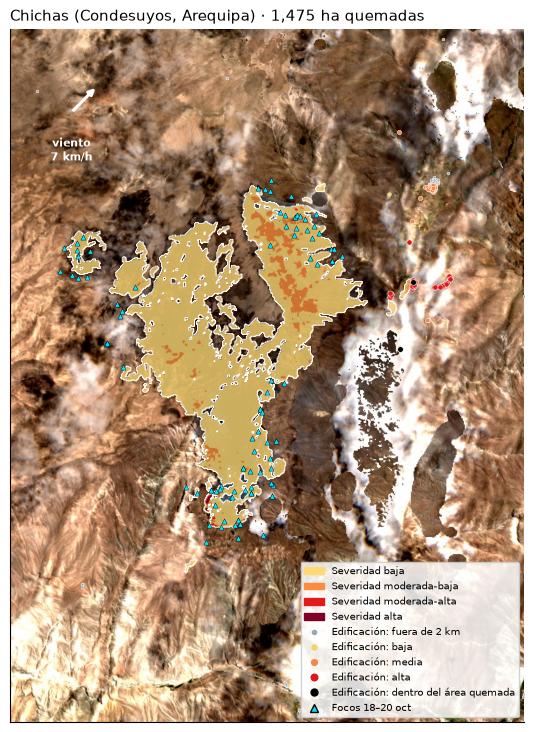

In [15]:
fig, ax = plt.subplots(figsize=(9, 9))
figuras.mapa_incendio("chichas", ax); plt.show()

El `full_plus_code` es la dirección Plus Code de cada edificación: se pega en Google Maps
para ubicarla. Así una tabla se vuelve una lista de visitas para Defensa Civil.

## 9 · Clima: ¿puede crecer esta semana?

Open-Meteo da 30 días hacia atrás y 7 de pronóstico, sin clave. Marcamos como **día crítico**
uno con humedad mínima < 30 %, ráfagas ≥ 30 km/h y lluvia < 1 mm.

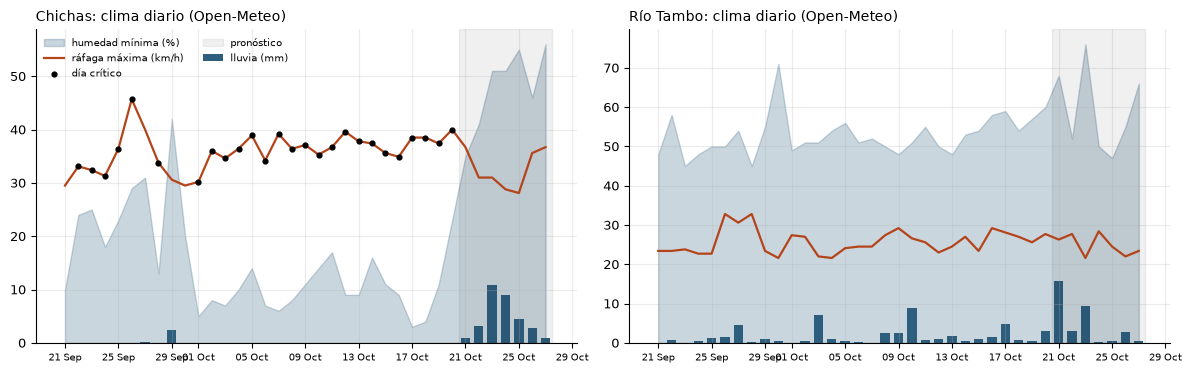

In [16]:
fig = figuras.clima(); plt.show()

Chichas ardió con **humedad mínima de 3–4 %** y ráfagas de ~38 km/h: todos los días de
octubre fueron críticos. El 19–20 subió la humedad y el pronóstico trae lluvia: no hay focos
desde el 18. En Río Tambo la humedad nunca bajó de 45 %: ese fuego no lo explica el clima,
sino quemas agrícolas en temporada seca.

## 10 · Río Tambo con el mismo flujo

Una sola llamada corre todo lo anterior para el segundo incendio. La selva es más difícil:
antes del fuego, la mejor imagen es del 28 de septiembre; después, ninguna está limpia, así
que se arma un **compuesto**: para cada píxel, la fecha limpia más reciente (20, 18 o 13 oct).

nubes después: {'2026-10-20': 46.5, '2026-10-18': 71.4, '2026-10-13': 17.9} → cobertura sin nubes 88.9 %
umbral por ruido: 0.242  (en Chichas fue 0.1)
área quemada: 2,695 ha


,cobertura,ha,%
0,Bosque,"2,653.50",98.40
1,Pastizal,40.20,1.50
2,Cultivo,1.70,0.10


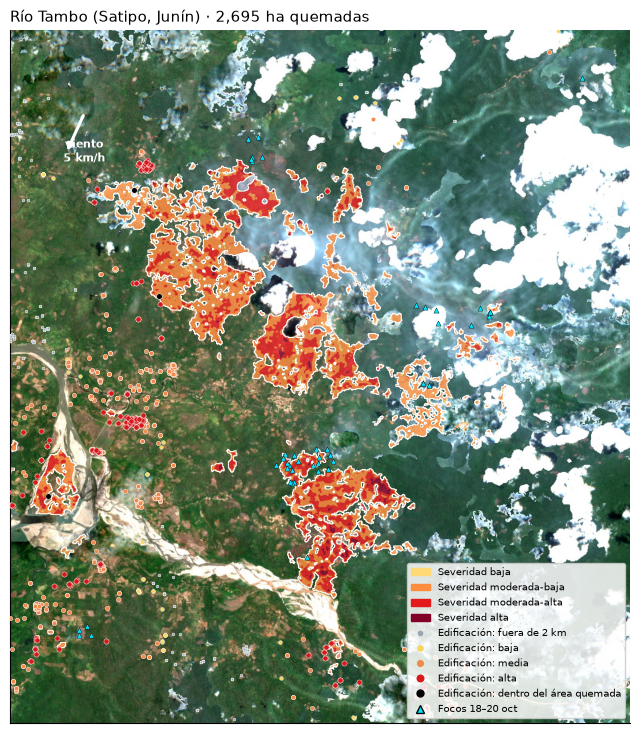

In [17]:
r_rt = json.loads((PROCESSED / "rio_tambo" / "resumen.json").read_text(encoding="utf-8"))
print("nubes después:", dict(zip(r_rt["post"], r_rt["nubes_post_pct"])),
      f'→ cobertura sin nubes {r_rt["cobertura_post_pct"]} %')
print(f'umbral por ruido: {r_rt["umbral_dnbr"]}  (en Chichas fue {r_ch["umbral_dnbr"]})')
print(f'área quemada: {r_rt["ha_quemadas"]:,.0f} ha')
display(pd.DataFrame(r_rt["por_cobertura"]))
fig, ax = plt.subplots(figsize=(9, 9))
figuras.mapa_incendio("rio_tambo", ax); plt.show()

## 11 · Tres hallazgos con números

In [18]:
def pct(a, b): return 100 * a / b
s27 = next(x["ha"] for x in r_ch["sensibilidad"] if x["umbral"] == 0.27 and x["sembrado_focos"])
print(f'''
1. Chichas: {r_ch["ha_quemadas"]:,.0f} ha quemadas en 3 días ({r_ch["por_cobertura"][0]["%"]:.0f} % pastizal),
   entre {r_ch["altitud_quemada_m"][0]:,} y {r_ch["altitud_quemada_m"][2]:,} m. Con el umbral clásico de 0,27 se
   habrían reportado solo {s27:,.0f} ha: el {100 - pct(s27, r_ch["ha_quemadas"]):.0f} % del fuego es de severidad baja.

2. Río Tambo: {r_rt["ha_quemadas"]:,.0f} ha, {r_rt["por_cobertura"][0]["%"]:.0f} % bosque, con {r_rt["focos_incendio"]:,} focos
   entre el 28 de septiembre y el 19 de octubre. Sigue activo: {r_rt["focos_72h"]} focos entre el 18 y el 20.

3. Edificaciones (Google Open Buildings) a ≤ 1 km del fuego: {r_rt["edificaciones_1km"]:,} en Río Tambo y
   {r_ch["edificaciones_1km"]} en Chichas. Con exposición alta: {r_rt["edificaciones"]["Alta"]} y {r_ch["edificaciones"]["Alta"]};
   ya dentro del área quemada: {r_rt["edificaciones"]["Dentro del área quemada"]} y {r_ch["edificaciones"]["Dentro del área quemada"]}.
''')


1. Chichas: 1,475 ha quemadas en 3 días (72 % pastizal),
   entre 3,337 y 4,112 m. Con el umbral clásico de 0,27 se
   habrían reportado solo 91 ha: el 94 % del fuego es de severidad baja.

2. Río Tambo: 2,695 ha, 98 % bosque, con 778 focos
   entre el 28 de septiembre y el 19 de octubre. Sigue activo: 48 focos entre el 18 y el 20.

3. Edificaciones (Google Open Buildings) a ≤ 1 km del fuego: 587 en Río Tambo y
   61 en Chichas. Con exposición alta: 265 y 57;
   ya dentro del área quemada: 4 y 2.



## Limitaciones

- **Un foco de calor no es un incendio.** El satélite pasa dos veces al día y no ve fuegos
  chicos, de corta duración ni bajo dosel cerrado.
- **Las nubes esconden el fuego.** En Río Tambo el 11 % de la zona no tiene ninguna
  observación limpia después del fuego: el área real puede ser mayor.
- **El umbral es una decisión.** El ruido se midió, pero 0,10 en sierra y 0,24 en selva
  siguen siendo elecciones; la tabla de sensibilidad muestra cuánto cambian las hectáreas.
- **Open Buildings detecta techos, no hogares.** Incluye corrales y depósitos, y las
  imágenes base son de hasta ~2023: faltan las construcciones nuevas y sobran las demolidas.
- **WorldCover es de 2021.** Bosque talado después figura todavía como bosque.
- **El índice de exposición no es un modelo de propagación.** Ordena edificaciones; no
  predice qué casa se quemará. Herramienta académica: no reemplaza a COEN, INDECI, SERFOR ni
  SERNANP.